# Check PSO Results

## Run and plot top 10 scoring parameters from PSO

In [17]:
import os
import sys
sys.path.insert(0, os.getcwd() + "/cellular_cycle") #add a pathway to the model #not sure about how to use folder dependency, to change
sys.path.insert(0, os.getcwd() + "/fit") #add a pathway to the fit functions #not sure about how to use folder dependency, to change

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
import sobol_seq

##Importing the model, models differ on their initial conditions, one being a concentration and the other a protein count
from Austin_proliferation_model_concentration_6 import model
model_concentration=model
# from Austin_proliferation_model_population_6 import model
from cell_cycle_death_model import model
model_population=model

##Import the simulator: for ODE and stochastic simulation :
from pysb.simulator import BngSimulator
from pysb.simulator import ScipyOdeSimulator


#change the model parameters of the model if needed
omega = 200
new_param = pd.read_csv(os.getcwd() + "/../Matlab/v2/parameters.csv") 
del new_param['Stress']
del new_param['K_sp21']
for key in new_param.keys():
    if model_population.parameters[key].value != new_param[key][0]:
        model_population.parameters[key].value = new_param[key]
    if model_concentration.parameters[key].value != new_param[key][0]:
        model_concentration.parameters[key].value = new_param[key]
model_concentration.parameters['omega'].value = 1

# Directory containing cell fate data
from pathlib import Path

DATADIR = Path('../Data/Exp_Intermitotic_Times/')

# Where to save large simulation output files
# SAVE_DIR = 'D:\\stoch_runs_230713\\'
SAVE_DIR = Path(Path.home(),'ECM_mode_output')
if not SAVE_DIR.exists():
    SAVE_DIR.mkdir()

OVERWRITE = False


In [2]:
t = np.linspace(0, 5000, 50001)
simres = ScipyOdeSimulator(model_concentration, t, verbose=False).run(); #deterministic simulation

In [3]:
model_population.parameters['ERK'].value = 1 * omega
model_population.parameters['FAK'].value = 1 * omega
model_population.parameters['AKT'].value = 1 * omega

model_concentration.parameters['ERK'].value = 1 * 1
model_concentration.parameters['FAK'].value = 1 * 1
model_concentration.parameters['AKT'].value = 1 * 1

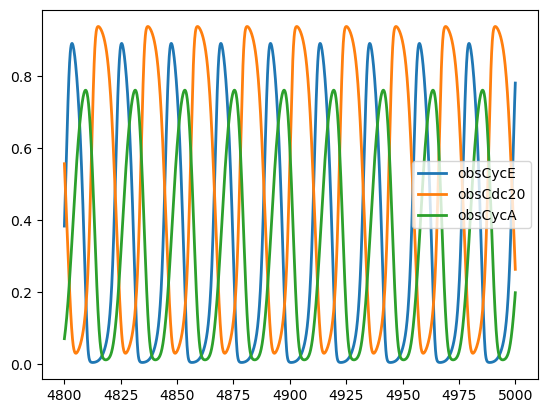

In [4]:
#ODE simulation

t = np.linspace(0, 5000, 50001)
simres = ScipyOdeSimulator(model_concentration, t, verbose=False).run(); #deterministic simulation
yout = simres.all;
observables=['obsCycE','obsCdc20', 'obsCycA']; #plot Cyclin E, Cdc20 and Cyclin A

for obs in range(3) :
    plt.plot(t[48000:],yout[observables[obs]][48000:], label=observables[obs], lw=2)
plt.legend(loc=0)
plt.show()

### Import PSO params

In [5]:
all_params = pd.read_csv(os.getcwd() + "/fit_data_parameters_pso_simulations_results.csv") 

In [6]:
all_params_cost = all_params.sort_values('cost.19')
param_names = all_params.iloc[0,56:92].values
top_costs = pd.DataFrame(data=all_params_cost.iloc[0:12,56:92].values, columns=param_names)

In [7]:
model_population.parameters['ERK'].value = 0.2 * omega
model_population.parameters['FAK'].value = 0.4 * omega
model_population.parameters['AKT'].value = 0.3 * omega

model_concentration.parameters['ERK'].value = 1.0 * 1 ###
model_concentration.parameters['FAK'].value = 0.4 * 1
model_concentration.parameters['AKT'].value = 0.6 * 1 ###

In [8]:
top_costs

,F_n,K_2E2F,K_CD,K_CE,K_DF,K_M,K_MY,K_S,K_p21fak,V_2E2F,...,k_RE,kasbaxmbcl2,kasbh3bcl2,kb,kdbh3,kdsbaxmbcl2,kdsbh3bcl2,kf1,kf2,v_s1p21
0,8.660157835133548,0.5621395275169132,0.5644458575249667,0.6380709428831556,0.9991830587539061,0.22235492626175005,0.11823659609669243,0.6149582357110128,5.731422835762793,0.7937957280409894,...,162.53488570722288,82.13468414735736,24.864078636023876,0.1610733741591959,0.030792602362104262,0.05661659506016427,0.009771592591933219,0.011329662336560662,2.434621453198629,0.6945858160211398
1,7.484264000493251,0.4874005303930365,0.6330748490577153,0.5394079277294466,0.9860238751696768,0.25822347827596287,0.09681274700096958,0.7394522629354493,4.810025523172703,0.7901944227103054,...,204.4849442203738,71.62215507648065,22.67169336385831,0.12892960367392625,0.03145046842601271,0.05339378684454702,0.013798459825059086,0.010852025887513887,2.2405725390073017,0.8017204599226264
2,8.660156335115666,0.5621394364610044,0.5644459217943505,0.6380707954547283,0.9991831849167221,0.22235495352956944,0.11823665537017898,0.6149583163289795,5.731421464391362,0.7937967498257777,...,162.53488880713456,82.1345666304622,24.864079276792754,0.16107335427403022,0.03079260821042765,0.05661659577246148,0.009771594092659945,0.0113296589873959,2.43462145245451,0.6945856557855021
3,7.369678964022715,0.4793095951076391,0.773632848663459,0.5344403447046063,0.9297296881086289,0.2444706732516184,0.10676309093673228,0.6993294458036725,4.901569537770841,0.8231158180131617,...,196.05567913616667,70.5236869544312,23.874776314468548,0.13805928878905935,0.029047834250766423,0.05754978893182192,0.01403534876881012,0.010756286391772512,2.451009593138619,0.7237924768485695
4,7.539330110290429,0.4892069979522081,0.6353802492815231,0.5395603320256815,0.9922653908188352,0.2584099537614839,0.09624426787004352,0.7268275168031549,4.858334759509059,0.7823021056447834,...,203.23428922723488,71.7669288814961,22.632806083197917,0.13116464699591326,0.032268716415661244,0.05407093063338088,0.013895174544256959,0.011015067898279237,2.2023290662969415,0.8049195971147562
5,7.27757519551836,0.47886659546814253,0.6467268457231851,0.5384346804304365,1.0026249768257907,0.26145513534702164,0.09747606047404811,0.7337532618975534,4.820909737372855,0.7943491925268447,...,200.861603388743,71.53554099386974,21.939366922240275,0.12955867338293364,0.03221138918694597,0.054688533748522034,0.014866963705222265,0.010633028359371393,2.231065995972585,0.8108823279536864
6,7.423290175471561,0.47921379005322245,0.6521094636975624,0.5154193876409188,1.017883101969731,0.2537210914650608,0.09317342174962277,0.7204248698719605,4.711768342596577,0.7617339946492802,...,195.11364274944594,69.579085927622,21.720905376527863,0.12970095886271274,0.03031447898133754,0.05466903025204324,0.015326702409327934,0.011445885091466037,2.243375888527698,0.7386354485151422
7,7.635013476659012,0.4947249022710766,0.6393828135981348,0.5398744408050848,1.01249048415486,0.2587512510039746,0.09476126767073996,0.7083669614242559,4.938644302400701,0.7634366745922987,...,201.10934265300168,71.98653196281265,22.555760687604387,0.1355895449524613,0.03331955310106319,0.055283395710350375,0.014132309782314133,0.011360742640837416,2.123481746590981,0.8090190885114591
8,7.395134421232209,0.5341860674176129,0.6395054690724278,0.5183016761625777,0.849651456959004,0.2073494436424903,0.09294560043982306,0.9308677026976887,4.759369226169339,0.8586497147381486,...,167.7964336833731,77.48114456099017,26.589267607429253,0.13512731162290967,0.03294175404794413,0.05139967611501416,0.010900390974238382,0.010982245483518428,2.2700087256291677,0.6198209821593568
9,7.404119735602079,0.48212543986202017,0.6416157143917036,0.5125816659990416,1.013699597406507,0.2535540885178903,0.09333709554059418,0.7626916973030394,4.810435677124986,0.7566127003063472,...,193.08208158049638,72.26871889225548,22.45296874949094,0.13316393214124575,0.03045814741596905,0.05531817136460191,0.015003663825766324,0.011691781832271158,2.35423953

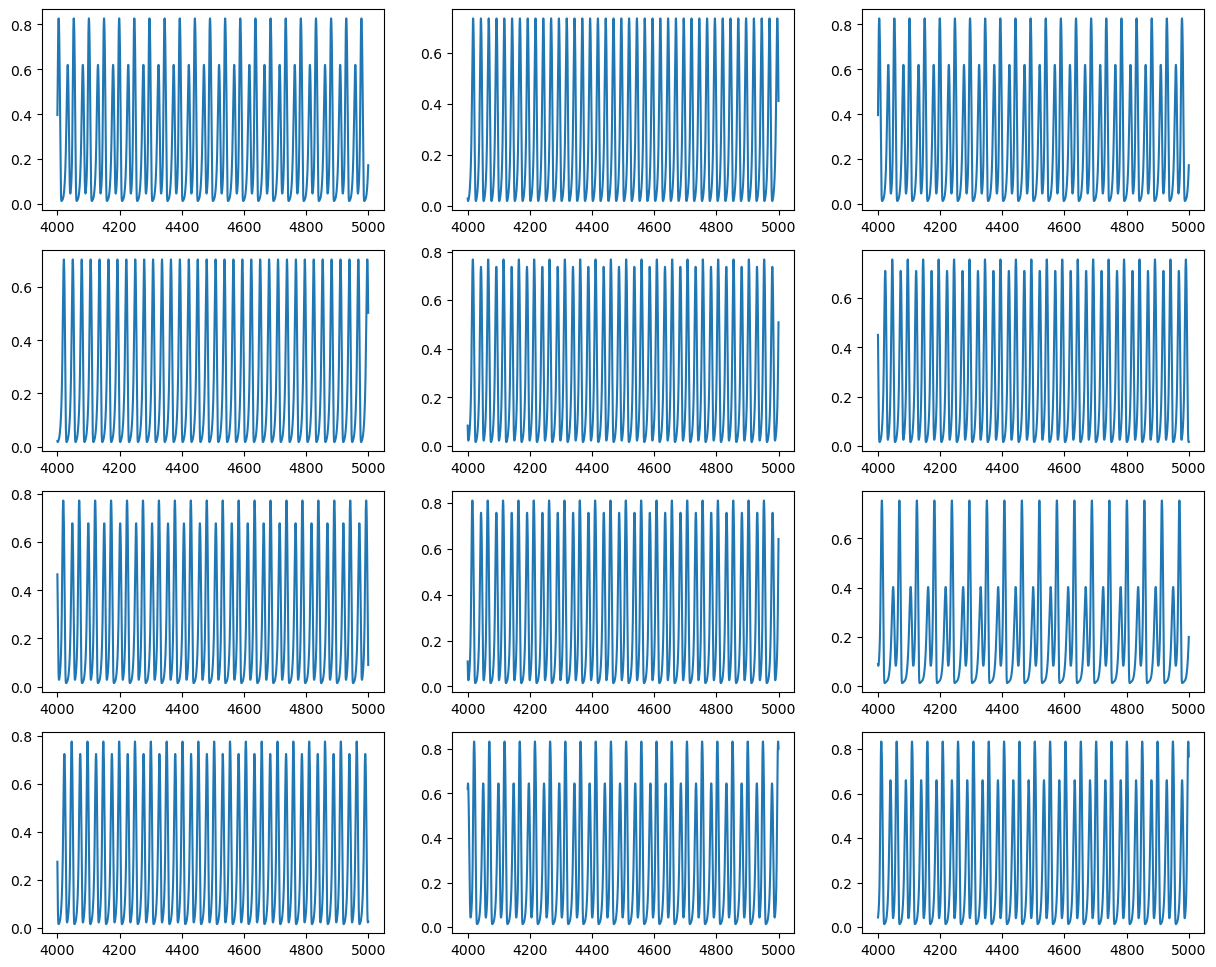

In [9]:
plt.figure(figsize=(15,12))

for num in range(len(top_costs)):
    for name in param_names:
        model_concentration.parameters[name].value = top_costs[name][num]

    simres = ScipyOdeSimulator(model_concentration, t, verbose=False).run(); #deterministic simulation
    yout = simres.all;
    observables=['obsCycE','obsCdc20', 'obsCycA']; #plot Cyclin E, Cdc20 and Cyclin A
    
    ax = plt.subplot(4, 3, num+1)
    
    plt.plot(t[40000:],yout['obsCdc20'][40000:], label=num)



### Run stochastic model

In [10]:
conditions = [
    {
        'AKT': 0.6,
        'ERK': 1,
        'FAK': 0.4
    },
    {
        'AKT': 1,
        'ERK': 1,
        'FAK': 0.6
    },
    {
        'AKT': 1,
        'ERK': 1,
        'FAK': 1
    },
    {
        'AKT': 0.3,
        'ERK': 0.2,
        'FAK': 0.4
    },
    {
        'AKT': 0.6,
        'ERK': 0.2,
        'FAK': 0.6
    },
    {
        'AKT': 0.6,
        'ERK': 0.2,
        'FAK': 1
    }
]

In [11]:
# SAVE_DIR = 'D:\\stoch_runs_230713\\'
for key in new_param.keys():
    if model_population.parameters[key].value != new_param[key][0]:
        model_population.parameters[key].value = new_param[key]
    if model_concentration.parameters[key].value != new_param[key][0]:
        model_concentration.parameters[key].value = new_param[key]
model_concentration.parameters['omega'].value = 1

t = np.linspace(0, 50000, 500001)

for condition in conditions:
    model_population.parameters['ERK'].value = condition['ERK'] * omega
    model_population.parameters['FAK'].value = condition['FAK'] * omega
    model_population.parameters['AKT'].value = condition['AKT'] * omega

    sim = BngSimulator(model_population, tspan=t, verbose=False); #stochastic simulator
    simres = sim.run(method='ssa', verbose=False, seed=33); #running the simulation; remove seed for truly random; seed=33 is used for similarity to deterministic sim
    yout = simres.observables;

    AKT = round(condition['AKT']*100)
    ERK = round(condition['ERK']*100)
    FAK = round(condition['FAK']*100)

    fname = Path(SAVE_DIR , f"AKT{AKT}_ERK{ERK}_FAK{FAK}_orig_long.csv")

    if OVERWRITE or not fname.is_file():
        print(f"Saving {fname}")
        np.savetxt(fname, yout, delimiter=',')
    else:
        print(f"Skipping {fname}")
    

In [12]:
# SAVE_DIR = 'D:\\stoch_runs_230713\\'
for key in new_param.keys():
    if model_population.parameters[key].value != new_param[key][0]:
        model_population.parameters[key].value = new_param[key]
    if model_concentration.parameters[key].value != new_param[key][0]:
        model_concentration.parameters[key].value = new_param[key]
model_concentration.parameters['omega'].value = 1
omega = 1

t = np.linspace(0, 50000, 500001)

for condition in conditions:
    model_concentration.parameters['ERK'].value = condition['ERK'] * omega
    model_concentration.parameters['FAK'].value = condition['FAK'] * omega
    model_concentration.parameters['AKT'].value = condition['AKT'] * omega

    simres = ScipyOdeSimulator(model_concentration, t, verbose=False, compiler='python').run(); #deterministic simulation
    yout = simres.observables;

    AKT = round(condition['AKT']*100)
    ERK = round(condition['ERK']*100)
    FAK = round(condition['FAK']*100)

    fname = Path(SAVE_DIR , f"AKT{AKT}_ERK{ERK}_FAK{FAK}_odeorig_long.csv")

    if OVERWRITE or not fname.exists():
        print(f"Saving {fname}")
        np.savetxt(fname, yout, delimiter=',')
    else:
        print(f"Skipping {fname}")
    

In [18]:
for num in range(2):
    for condition in conditions:
        for name in param_names:
            model_concentration.parameters[name].value = top_costs[name][num]

        model_population.parameters['ERK'].value = condition['ERK'] * omega
        model_population.parameters['FAK'].value = condition['FAK'] * omega
        model_population.parameters['AKT'].value = condition['AKT'] * omega
        
        sim = BngSimulator(model_population, tspan=t, verbose=False); #stochastic simulator
        simres = sim.run(method='ssa', verbose=False, seed=33); #running the simulation; remove seed for truly random; seed=33 is used for similarity to deterministic sim
        yout = simres.observables;
        
        AKT = round(condition['AKT']*100)
        ERK = round(condition['ERK']*100)
        FAK = round(condition['FAK']*100)
        
        fname = Path(SAVE_DIR , f"AKT{AKT}_ERK{ERK}_FAK{FAK}_param{num}.csv")

        if OVERWRITE or not fname.exists():
            print(f"Saving {fname}")
            np.savetxt(fname, yout, delimiter=',')
        else:
            print(f"Skipping {fname}")
            
        
        

Saving /Users/darren/ECM_mode_output/AKT60_ERK100_FAK40_param0.csv
Saving /Users/darren/ECM_mode_output/AKT100_ERK100_FAK60_param0.csv
Saving /Users/darren/ECM_mode_output/AKT100_ERK100_FAK100_param0.csv
Saving /Users/darren/ECM_mode_output/AKT30_ERK20_FAK40_param0.csv
Saving /Users/darren/ECM_mode_output/AKT60_ERK20_FAK60_param0.csv
Saving /Users/darren/ECM_mode_output/AKT60_ERK20_FAK100_param0.csv
Saving /Users/darren/ECM_mode_output/AKT60_ERK100_FAK40_param1.csv
Saving /Users/darren/ECM_mode_output/AKT100_ERK100_FAK60_param1.csv
Saving /Users/darren/ECM_mode_output/AKT100_ERK100_FAK100_param1.csv
Saving /Users/darren/ECM_mode_output/AKT30_ERK20_FAK40_param1.csv
Saving /Users/darren/ECM_mode_output/AKT60_ERK20_FAK60_param1.csv
Saving /Users/darren/ECM_mode_output/AKT60_ERK20_FAK100_param1.csv


### Calc UMAP and plot

In [19]:
import pandas as pd
import numpy as np
import umap
import joblib
from pathlib import Path
import os
import glob

In [20]:
file_location = os.path.join(SAVE_DIR, '*_orig_long.csv')
filenames = glob.glob(file_location)
filenames = sorted(filenames)
filenames_sp = [filenames[3], filenames[2], filenames[1], filenames[5], filenames[0], filenames[4]]
filenames_sp

['/Users/darren/ECM_mode_output/AKT60_ERK100_FAK40_orig_long.csv',
 '/Users/darren/ECM_mode_output/AKT30_ERK20_FAK40_orig_long.csv',
 '/Users/darren/ECM_mode_output/AKT100_ERK100_FAK60_orig_long.csv',
 '/Users/darren/ECM_mode_output/AKT60_ERK20_FAK60_orig_long.csv',
 '/Users/darren/ECM_mode_output/AKT100_ERK100_FAK100_orig_long.csv',
 '/Users/darren/ECM_mode_output/AKT60_ERK20_FAK100_orig_long.csv']

In [21]:
file_location = os.path.join(SAVE_DIR, '*odeorig_long.csv')
filenames_ode = glob.glob(file_location)
filenames_ode = sorted(filenames_ode)
filenames_sp_ode = [filenames_ode[3], filenames_ode[2], filenames_ode[1], filenames_ode[5], filenames_ode[0], filenames_ode[4]]
filenames_sp_ode

['/Users/darren/ECM_mode_output/AKT60_ERK100_FAK40_odeorig_long.csv',
 '/Users/darren/ECM_mode_output/AKT30_ERK20_FAK40_odeorig_long.csv',
 '/Users/darren/ECM_mode_output/AKT100_ERK100_FAK60_odeorig_long.csv',
 '/Users/darren/ECM_mode_output/AKT60_ERK20_FAK60_odeorig_long.csv',
 '/Users/darren/ECM_mode_output/AKT100_ERK100_FAK100_odeorig_long.csv',
 '/Users/darren/ECM_mode_output/AKT60_ERK20_FAK100_odeorig_long.csv']

In [22]:
#The filenames to make the reducer umap object from
"""
filenames = ['erl_4-9_1_1.txt', 'erl_4-9_2_1.txt', 'erl_4-9_3_1.txt',
             'dmso_4-9_1_1.txt', 'dmso_4-9_2_1.txt', 'dmso_4-9_3_1.txt']
#Important params to set the window size and step time distance
init_dt = 0.01                #initial dt from the raw model output
dt = 0.1                      #dt for umap window
window = 4                    #window size in hours
time_step = 1                 #time step between windows

#umap params
neighbs = 100
min_d = 0.02
"""
# Important params to set the window size and step time distance
init_dt = 0.1                # initial dt from the raw model output
dt = 0.1                      # dt for umap window
window = 2                    # window size in hours
time_step = 0.5               # time step between windows

#umap params
neighbs = 25
min_d = 0.05

#reducer save name
r_name = f'reducer_07_13_{init_dt}_{dt}_{window}_{time_step}.sav'

In [23]:
def plot_phase(filenames, filenames_ode):
    sf = 1
    fig = plt.figure()
    for (f, f_ode) in zip(filenames, filenames_ode):
        prot_tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
        prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp = prot_tmp.drop(columns=['cdh1_inact'])
        prot_tmp = prot_tmp/200
        prot_tmp[prot_tmp<0] = 0 #from old extrap. method, don't think I need this
        
        prot_tmp_ode = pd.read_csv(f_ode, sep=",", header=None, usecols = range(0,19))
        prot_tmp_ode.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp_ode = prot_tmp_ode.drop(columns=['cdh1_inact'])
        prot_tmp_ode[prot_tmp_ode<0] = 0 #from old extrap. method, don't think I need this 
        
        plt.subplot(3,2,sf)
        
        plt.plot(prot_tmp['cycE'], prot_tmp['cdc20'], lw=0.25, alpha=0.75, c='gray')
        plt.plot(prot_tmp_ode.iloc[-10000:,11], prot_tmp_ode.iloc[-10000:,17], lw=1, alpha=1, c='black')
        
        plt.xlim(0,1)
        plt.ylim(0,1)

        ax = plt.gca()
        if (sf % 2) == 0:
            ax.yaxis.set_tick_params(labelleft=False)
        if sf<5:
            ax.xaxis.set_tick_params(labelleft=False)
        
        sf += 1
        
    # Set common labels
    fig.text(0.5, 0.04, 'cyclin E', ha='center', va='center')
    fig.text(0.06, 0.5, 'cdc20', ha='center', va='center', rotation='vertical')
    

In [24]:
def plot_phase_norm(filenames, filenames_ode, max_prots, min_prots):
    sf = 1
    fig = plt.figure()
    for (f, f_ode) in zip(filenames, filenames_ode):
        prot_tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
        prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp = prot_tmp.drop(columns=['cdh1_inact'])
        prot_tmp = prot_tmp/200
        prot_tmp[prot_tmp<0] = 0 #from old extrap. method, don't think I need this
        
        prot_tmp_ode = pd.read_csv(f_ode, sep=",", header=None, usecols = range(0,19))
        prot_tmp_ode.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp_ode = prot_tmp_ode.drop(columns=['cdh1_inact'])
        prot_tmp_ode[prot_tmp_ode<0] = 0 #from old extrap. method, don't think I need this 
        
        for ii in range(18):
            prot_tmp.iloc[:,ii] = (prot_tmp.iloc[:,ii] - min_prots[ii])/(max_prots[ii] - min_prots[ii])
            prot_tmp_ode.iloc[:,ii] = (prot_tmp_ode.iloc[:,ii] - min_prots[ii])/(max_prots[ii] - min_prots[ii])
        
        plt.subplot(3,2,sf)
        
        plt.plot(prot_tmp['cycE'], prot_tmp['cdc20'], lw=0.25, alpha=0.75, c='gray')
        plt.plot(prot_tmp_ode.iloc[-10000:,11], prot_tmp_ode.iloc[-10000:,17], lw=1, alpha=1, c='black')
        
        plt.xlim(0,1)
        plt.ylim(0,1)

        ax = plt.gca()
        if (sf % 2) == 0:
            ax.yaxis.set_tick_params(labelleft=False)
        if sf<5:
            ax.xaxis.set_tick_params(labelleft=False)
        
        sf += 1
        
    # Set common labels
    fig.text(0.5, 0.04, 'cyclin E', ha='center', va='center')
    fig.text(0.06, 0.5, 'cdc20', ha='center', va='center', rotation='vertical')
    
    

In [25]:
def load_norm_data(filenames, filenames_ode, time_all, init_dt, dt, window, time_step, plot_phase):
    max_prots=[0]*18
    min_prots=[1000]*18
    
    for f in filenames:
        tmp_max=[]
        tmp_min=[]
        prot_tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
        prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp = prot_tmp.drop(columns=['cdh1_inact'])
        prot_tmp = prot_tmp/200
        prot_tmp[prot_tmp<0] = 0 #from old extrap. method, don't think I need this
        
        tmp_max = [prot_tmp[col].max() for col in prot_tmp]
        tmp_min = [prot_tmp[col].min() for col in prot_tmp]
        
        max_prots = [max(max_prots[n], tmp_max[n]) for n in range(18)]
        min_prots = [min(min_prots[n], tmp_min[n]) for n in range(18)]
        
    for f in filenames_ode:
        tmp_max=[]
        tmp_min=[]
        prot_tmp_ode = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
        prot_tmp_ode.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp_ode = prot_tmp_ode.drop(columns=['cdh1_inact'])
        prot_tmp[prot_tmp<0] = 0 #from old extrap. method, don't think I need this
        
        tmp_max = [prot_tmp_ode[col].max() for col in prot_tmp_ode]
        tmp_min = [prot_tmp_ode[col].min() for col in prot_tmp_ode]
        
        max_prots = [max(max_prots[n], tmp_max[n]) for n in range(18)]
        min_prots = [min(min_prots[n], tmp_min[n]) for n in range(18)]  
    
    if plot_phase:
        plot_phase(filenames_sp, filenames_sp_ode)
        plt.savefig(SAVE_DIR + f"phaseplot_{num}.png", bbox_inches='tight')
        plot_phase_norm(filenames_sp, filenames_sp_ode, max_prots, min_prots)
        plt.savefig(SAVE_DIR + f"phaseplot_norm_{num}.png", bbox_inches='tight')
    
    win_len = int(window/dt)
    all_prot_tmp = np.empty((0,win_len*18))     #careful, this could end up being massive 
    all_prot_tmp_ode = np.empty((0,win_len*18))
    all_time_tmp = np.empty((0,win_len))
    all_time_at_tmp = np.empty((0,1))
    range_ind = np.arange(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt))
        
    for (f, f_ode) in zip(filenames, filenames_ode):
        prot_tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
        prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp = prot_tmp.drop(columns=['cdh1_inact'])
        prot_tmp = prot_tmp/200
        for ii in range(18):
            prot_tmp.iloc[:,ii] = (prot_tmp.iloc[:,ii] - min_prots[ii])/(max_prots[ii] - min_prots[ii])

        prot_re_tmp = np.empty((len(range_ind),win_len*18))
        time_re_tmp = np.empty((len(range_ind),win_len))
        time_at_tmp = np.empty((len(range_ind),1))

        ii=0
        for n in range(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt)):
            tmp = prot_tmp.iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp_t = time_tmp2['time'].iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp=tmp.to_numpy()
            tmp=np.reshape(np.transpose(tmp),win_len*18)
            tmp_at = time_tmp2['time'].iloc[n]

            prot_re_tmp[ii,:] = np.array([tmp])
            time_re_tmp[ii,:] = np.array([tmp_t])
            time_at_tmp[ii,:] = np.array([[tmp_at]])
            ii+=1

        all_prot_tmp = np.append(all_prot_tmp, prot_re_tmp, axis=0)
        all_time_tmp = np.append(all_time_tmp, time_re_tmp, axis=0)
        all_time_at_tmp = np.append(all_time_at_tmp, time_at_tmp, axis=0)
        
        prot_tmp_ode = pd.read_csv(f_ode, sep=",", header=None, usecols = range(0,19))
        prot_tmp_ode.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp_ode = prot_tmp_ode.drop(columns=['cdh1_inact'])
        for ii in range(18):
            prot_tmp_ode.iloc[:,ii] = (prot_tmp_ode.iloc[:,ii] - min_prots[ii])/(max_prots[ii] - min_prots[ii])

        prot_re_tmp = np.empty((len(range_ind),win_len*18))


        ii=0
        for n in range(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt)):
            tmp = prot_tmp_ode.iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp=tmp.to_numpy()
            tmp=np.reshape(np.transpose(tmp),win_len*18)

            prot_re_tmp[ii,:] = np.array([tmp])
            time_re_tmp[ii,:] = np.array([tmp_t])
            time_at_tmp[ii,:] = np.array([[tmp_at]])
            ii+=1

        all_prot_tmp_ode = np.append(all_prot_tmp_ode, prot_re_tmp, axis=0)
        
    return all_prot_tmp, all_prot_tmp_ode, all_time_tmp, all_time_at_tmp
        

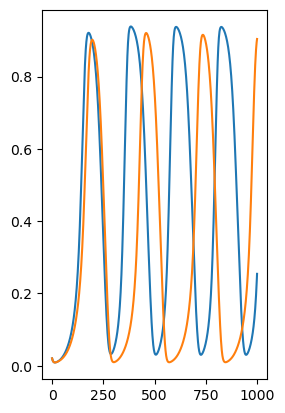

In [26]:
prot_tmp_ode = pd.read_csv(filenames_ode[0], sep=",", header=None, usecols = range(0,19))
prot_tmp_ode.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
"Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
"cycB", "cycB-p21", "cdc20"]
prot_tmp_ode = prot_tmp_ode.drop(columns=['cdh1_inact'])
fig = plt.figure()

plt.subplot(1,2,1)
plt.plot(prot_tmp_ode.iloc[:1000,17])
prot_tmp_ode = pd.read_csv(filenames_ode[4], sep=",", header=None, usecols = range(0,19))
prot_tmp_ode.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
"Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
"cycB", "cycB-p21", "cdc20"]
prot_tmp_ode = prot_tmp_ode.drop(columns=['cdh1_inact'])
plt.subplot(1,2,1)
plt.plot(prot_tmp_ode.iloc[:1000,17])


In [27]:
time_tmp = np.linspace(0, 50000, 500001)
time_tmp2 = pd.DataFrame(data=time_tmp)
time_tmp2.columns = ["time"]
plot_phase = False

In [28]:
[all_prot_tmp, all_prot_tmp_ode, all_time_tmp, all_time_at_tmp] = load_norm_data(filenames_sp, filenames_sp_ode, time_tmp2, init_dt, dt, window, time_step, plot_phase)

In [29]:
len(all_prot_tmp)

599982

In [30]:
len(all_prot_tmp_ode)

599982

In [31]:
reducer = umap.UMAP(
        n_neighbors=neighbs,
        min_dist=min_d,
        n_components=2,
        metric='euclidean',
        random_state=5,
        low_memory=True        
        ).fit(all_prot_tmp)

embedding_all_prot = reducer.transform(all_prot_tmp)

In [32]:
win_len = int(window/dt)
all_prot_tmp_ode_ab = np.empty((0,win_len*18))
ab_len = (len(all_prot_tmp_ode)/6/8)*7
w_len = len(all_prot_tmp_ode)/6
sp = 1
for n in range(6):
    tmp = all_prot_tmp_ode[int(n*w_len+ab_len):int(sp*w_len),:]
    all_prot_tmp_ode_ab = np.append(all_prot_tmp_ode_ab, tmp, axis=0)
    sp += 1

embedding_all_prot_ode = reducer.transform(all_prot_tmp_ode_ab)

In [33]:
int(len(embedding_all_prot_ode)/6)

12500

Text(0.06, 0.77, 'Soft')

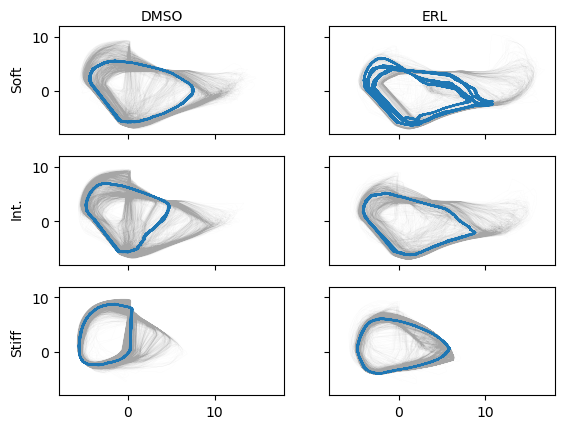

In [34]:
fig = plt.figure()
n1 = 1
for n in range(6):
    plt.subplot(3,2,n1)
    trk_len = int(len(embedding_all_prot)/6)
    trk_len_ode = int(len(embedding_all_prot_ode)/6)
    plt.plot(embedding_all_prot[n*trk_len:n1*trk_len,0], embedding_all_prot[n*trk_len:n1*trk_len,1], lw=0.01, alpha=0.7, c='gray')
    plt.plot(embedding_all_prot_ode[n*trk_len_ode:n1*trk_len_ode,0], embedding_all_prot_ode[n*trk_len_ode:n1*trk_len_ode,1], lw=1, alpha=1)

    plt.xlim(-8,18)
    plt.ylim(-8,12)

    ax = plt.gca()
    if (n1 % 2) == 0:
        ax.yaxis.set_tick_params(labelleft=False)
    if n1<5:
        ax.xaxis.set_tick_params(labelleft=False)
    n1 += 1

# Set common labels
fig.text(0.287, 0.9, 'DMSO', ha='center', va='center')
fig.text(0.713, 0.9, 'ERL', ha='center', va='center')
fig.text(0.06, 0.22, 'Stiff', ha='center', va='center', rotation='vertical')
fig.text(0.06, 0.5, 'Int.', ha='center', va='center', rotation='vertical')
fig.text(0.06, 0.77, 'Soft', ha='center', va='center', rotation='vertical')
# plt.savefig(SAVE_DIR + f"UMAP_neighbs{neighbs}_window{window}_tstep{time_step}_ORIG.png", bbox_inches='tight')

In [35]:
trk_len = int(len(all_prot_tmp)/6)
y_label_list = ['Skp2', 'p21', 'pp21', 'Cdh1', 'Myc', 'CycD', 'CycDp21', 'Rb', 'pRb', 'E2F', 'RbE2F',
                'CycE', 'CycEp21', 'CycA', 'CycAp21', 'CycB', 'CycBp21', 'Cdc20']
erl_int_prot_df = pd.DataFrame(all_prot_tmp[3*trk_len:4*trk_len,:])
erl_int_time_df = pd.DataFrame(all_time_tmp[3*trk_len:4*trk_len,:])
erl_int_emb_df = pd.DataFrame(embedding_all_prot[3*trk_len:4*trk_len,:])

In [36]:
def restructProt(protDF, embedDF, timeDF):
    peaks_E, _ = find_peaks(protDF.iloc[:,int((win_len*11+win_len/2)-1)], prominence = 40/200, distance = 10)
    peaks_cdc, _ = find_peaks(protDF.iloc[:,int((win_len*17+win_len/2)-1)], prominence = 40/200, distance = 10)
    
    mit_win = pd.DataFrame()
    time_win = pd.DataFrame()
    umap_win = pd.DataFrame()
    num = 1
    
    for n in range(2,len(peaks_cdc)-3):   #make sure we have divisions at ends 
        tmp_mit = peaks_cdc[n]
        tmp_mit2 = peaks_cdc[n+1]
        tmp_mit3 = peaks_cdc[n+2]
        tmp_mit4 = peaks_cdc[n+3]
        
        tmp_g1_s = peaks_E[(tmp_mit < peaks_E) & (peaks_E < tmp_mit2)]
        tmp_g1_s_2 = peaks_E[(tmp_mit2 < peaks_E) & (peaks_E < tmp_mit3)]
        tmp_g1_s_3 = peaks_E[(tmp_mit3 < peaks_E) & (peaks_E < tmp_mit4)]    
             
        if (np.size(tmp_g1_s) > 0) & (np.size(tmp_g1_s_2)>0) & (np.size(tmp_g1_s_3)>0):
            ordered = [tmp_mit, tmp_g1_s[0], tmp_mit2, tmp_g1_s_2[0], tmp_mit3, tmp_g1_s_3[0], tmp_mit4]
            g1_len_tmp = np.array(timeDF.iloc[ordered[3],0]) - np.array(timeDF.iloc[[ordered[2]],0])
            tmp_prot = protDF.iloc[int(ordered[1]):int(ordered[3]),:]
            tmp_umap = embedDF.iloc[int(ordered[1]):int(ordered[3]),:]
            tmp_time = timeDF.iloc[int(ordered[1]):int(ordered[3]),:]
            tmp = [g1_len_tmp]*len(tmp_time)
            tmp_g1s = [int(ordered[1])]*len(tmp_time)
            tmp_mit = [int(ordered[2])]*len(tmp_time)
            tmp_g1s2 = [int(ordered[3])]*len(tmp_time)
            
            tmp_time.insert(0, 'G1-S_2', tmp_g1s2)
            tmp_time.insert(0, 'mit', tmp_mit)
            tmp_time.insert(0, 'G1-S', tmp_g1s)
            tmp_time.insert(0, 'G1_len', tmp)
            tmp_time.insert(0, 'div', [num]*len(tmp_time))
            num += 1
            
            mit_win = pd.concat([mit_win,tmp_prot],ignore_index=True)
            time_win = pd.concat([time_win, tmp_time], ignore_index=True)
            umap_win = pd.concat([umap_win, tmp_umap], ignore_index=True)
            
    return mit_win, time_win, umap_win

In [37]:
from scipy.signal import find_peaks

In [38]:
mit_win_erl_int, time_win_erl_int, umap_win_erl_int = restructProt(erl_int_prot_df, erl_int_emb_df, erl_int_time_df)

Text(0.5, 1.0, 'Cdc20')

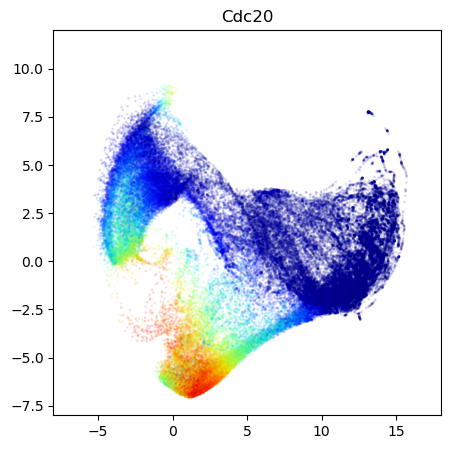

In [39]:
xmin, xmax = -8, 18
ymin, ymax = -8, 12
n=17

fig = plt.figure()
ax = fig.gca()
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
fig.set_size_inches(5, 5)
plt.scatter(umap_win_erl_int[0],umap_win_erl_int[1],c=mit_win_erl_int[int((win_len*n+win_len/2)-1)],s=1,cmap='jet',
           alpha=0.1)
plt.clim(0, 1)
plt.title(y_label_list[n])

In [40]:

timewinDF=time_win_erl_int
protDF=erl_int_prot_df
t_before_div=10
t_step = 0.5
short_len = 35
long_len = 30

divDF = pd.DataFrame()
all_imts = []

tmpDF = timewinDF.loc[timewinDF['div'] == 2]


In [41]:
tmpDF.iloc[0,3]-int(t_before_div/t_step)

310

In [42]:
tmpDF

,div,G1_len,G1-S,mit,G1-S_2,0,1,2,3,4,...,10,11,12,13,14,15,16,17,18,19
50,2,[44.5],309,330,419,154.5,154.6,154.7,154.8,154.9,...,155.5,155.6,155.7,155.8,155.9,156.0,156.1,156.2,156.3,156.4
51,2,[44.5],309,330,419,155.0,155.1,155.2,155.3,155.4,...,156.0,156.1,156.2,156.3,156.4,156.5,156.6,156.7,156.8,156.9
52,2,[44.5],309,330,419,155.5,155.6,155.7,155.8,155.9,...,156.5,156.6,156.7,156.8,156.9,157.0,157.1,157.2,157.3,157.4
53,2,[44.5],309,330,419,156.0,156.1,156.2,156.3,156.4,...,157.0,157.1,157.2,157.3,157.4,157.5,157.6,157.7,157.8,157.9
54,2,[44.5],309,330,419,156.5,156.6,156.7,156.8,156.9,...,157.5,157.6,157.7,157.8,157.9,158.0,158.1,158.2,158.3,158.4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
155,2,[44.5],309,330,419,207.0,207.1,207.2,207.3,207.4,...,208.0,208.1,208.2,208.3,208.4,208.5,208.6,208.7,208.8,208.9
156,2,[44.5],309,330,419,207.5,207.6,207.7,207.8,207.9,...,208.5,208.6,208.7,208.8,208.9,209.0,209.1,209.2,209.3,209.4
157,2,[44.5],309,330,419,208.0,208.1,208.2,208.3,208.4,...,209.0,209.1,209.2,209.3,209.4,209.5,209.6,209.7,209.8,209.9
158,2,[44.5],309,330,419,208.5,208.6,208.7,208.8,208.9,...,209.5,209.6,209.7,209.8,209.9,210.0,210.1,210.2,210.3,210.4


In [43]:
def splitG1(timewinDF, protDF, t_before_div):
    # t_before_div - time in hours (0.5 hour increments)
    t_step = 0.5
    short_len = 35
    long_len = 30
    
    divDF = pd.DataFrame()
    all_imts = []
    
    for n in timewinDF['div'].unique():
        tmpDF = timewinDF.loc[timewinDF['div'] == n]
        
        if tmpDF.iloc[0,1][0] <= short_len:
            tmp = np.array(protDF.iloc[tmpDF.iloc[0,3]-int(t_before_div/t_step),:])
            tmp = np.append(tmp, int(0))
            tmp = tmp.reshape(-1,len(tmp))
            indDF = pd.DataFrame(tmp)
            divDF = pd.concat([divDF,indDF],ignore_index=True)
#         elif (tmpDF.iloc[0,1][0] > short_len) & (tmpDF.iloc[0,1][0] <= long_len):
#             tmp = np.array(protDF.iloc[tmpDF.iloc[0,3]-int(t_before_div/t_step),:])
#             tmp = np.append(tmp, int(1))
#             tmp = tmp.reshape(-1,len(tmp))
#             indDF = pd.DataFrame(tmp)
#             divDF = pd.concat([divDF,indDF],ignore_index=True)
        else:
            tmp = np.array(protDF.iloc[tmpDF.iloc[0,3]-int(t_before_div/t_step),:])
            tmp = np.append(tmp, int(1))
            tmp = tmp.reshape(-1,len(tmp))
            indDF = pd.DataFrame(tmp)
            divDF = pd.concat([divDF,indDF],ignore_index=True)
            
        all_imts.append(tmpDF.iloc[0,1][0])
    return divDF, all_imts
    
    
    

        

In [44]:
dataset, imts_erl_int = splitG1(time_win_erl_int, erl_int_prot_df, 0)

(array([0.        , 0.        , 0.        , 0.00181488, 0.00272232,
        0.00453721, 0.02087114, 0.01270417, 0.01179673, 0.01724138,
        0.02450091, 0.02268603, 0.02631579, 0.02177858, 0.03085299,
        0.03811252, 0.03448276, 0.02177858, 0.02631579, 0.03266788,
        0.02722323, 0.02903811, 0.03266788, 0.01633394, 0.02813067,
        0.03085299, 0.02631579, 0.02813067, 0.02177858, 0.01633394,
        0.02177858, 0.02177858, 0.02359347, 0.01451906, 0.0154265 ,
        0.01270417, 0.01451906, 0.01088929, 0.00816697, 0.01814882,
        0.01179673, 0.00998185, 0.01361162, 0.01451906, 0.00816697,
        0.00272232, 0.01088929, 0.00816697, 0.00816697, 0.01270417,
        0.00635209, 0.00907441, 0.00453721, 0.00181488, 0.00635209,
        0.00816697, 0.00362976, 0.00453721, 0.00725953, 0.00453721,
        0.00181488, 0.00362976, 0.00272232, 0.00453721, 0.00181488,
        0.00544465, 0.00090744, 0.00362976, 0.00090744, 0.00544465,
        0.00090744, 0.00272232, 0.00362976, 0.00

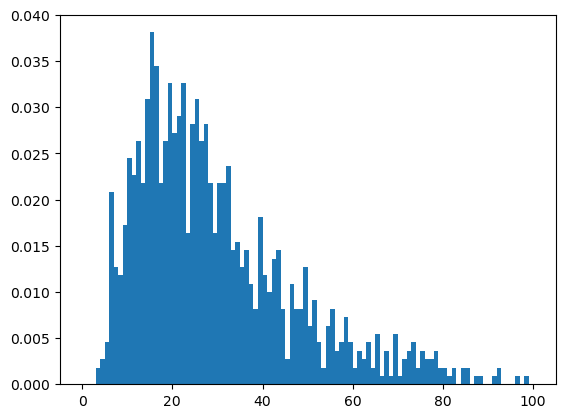

In [45]:
fig = plt.figure()
plt.hist(imts_erl_int, bins=np.arange(0,101,1), density=True)

In [46]:
X = dataset.iloc[:, 9::20].values

In [47]:
X.shape

(1103, 18)

In [48]:
#X = dataset.iloc[:, :-1].values
y = dataset.iloc[:, -1].values

In [49]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 0)

In [50]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

In [51]:
reducer_1 = umap.UMAP(
        n_neighbors=10,
        min_dist=0.02,
        n_components=2,
        metric='euclidean',
        random_state=5,
        low_memory=True        
        ).fit(X_train)

embedding_X_train = reducer_1.transform(X_train)

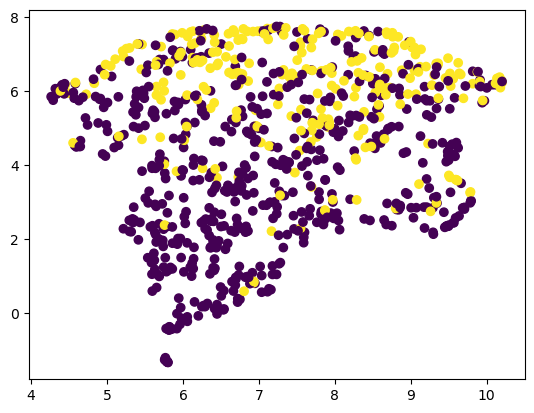

In [52]:
plt.figure()
plt.scatter(embedding_X_train[:,0], embedding_X_train[:,1], c=y_train)

In [53]:
from sklearn.decomposition import KernelPCA
kpca = KernelPCA(n_components = 2, kernel = 'rbf')
X_PCA = kpca.fit_transform(X_train)


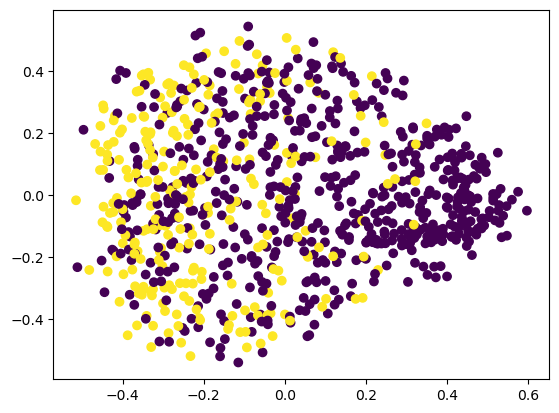

In [54]:
plt.figure()
plt.scatter(X_PCA[:,0], X_PCA[:,1], c=y_train)

### Logistic Regression

In [55]:
from sklearn.linear_model import LogisticRegression
classifier = LogisticRegression(random_state = 0)
classifier.fit(X_train, y_train)
y_pred = classifier.predict(X_test)

In [56]:
from sklearn.model_selection import cross_val_score
accuracies = cross_val_score(estimator = classifier, X = X_train, y = y_train, cv = 10)
print("Accuracy: {:.2f} %".format(accuracies.mean()*100))
print("Standard Deviation: {:.2f} %".format(accuracies.std()*100))

Accuracy: 80.50 %
Standard Deviation: 3.09 %


### K-NN

In [57]:
from sklearn.neighbors import KNeighborsClassifier
classifier = KNeighborsClassifier(n_neighbors = 5, metric = 'minkowski', p = 2)
classifier.fit(X_train, y_train)

KNeighborsClassifier()

In [58]:
from sklearn.model_selection import cross_val_score
accuracies = cross_val_score(estimator = classifier, X = X_train, y = y_train, cv = 10)
print("Accuracy: {:.2f} %".format(accuracies.mean()*100))
print("Standard Deviation: {:.2f} %".format(accuracies.std()*100))

Accuracy: 75.63 %
Standard Deviation: 3.13 %


### Kernal SVM

In [59]:
from sklearn.svm import SVC
classifier = SVC(kernel = 'rbf', random_state = 0)
classifier.fit(X_train, y_train)

SVC(random_state=0)

In [60]:
from sklearn.model_selection import cross_val_score
accuracies = cross_val_score(estimator = classifier, X = X_train, y = y_train, cv = 10)
print("Accuracy: {:.2f} %".format(accuracies.mean()*100))
print("Standard Deviation: {:.2f} %".format(accuracies.std()*100))

Accuracy: 78.80 %
Standard Deviation: 1.71 %


### Random Forest

In [61]:
from sklearn.ensemble import RandomForestClassifier
classifier = RandomForestClassifier(n_estimators = 10, criterion = 'entropy', random_state = 0)
classifier.fit(X_train, y_train)

RandomForestClassifier(criterion='entropy', n_estimators=10, random_state=0)

In [62]:
from sklearn.model_selection import cross_val_score
accuracies = cross_val_score(estimator = classifier, X = X_train, y = y_train, cv = 10)
print("Accuracy: {:.2f} %".format(accuracies.mean()*100))
print("Standard Deviation: {:.2f} %".format(accuracies.std()*100))

Accuracy: 76.87 %
Standard Deviation: 3.70 %


### Naive Bayes

In [63]:
from sklearn.naive_bayes import GaussianNB
classifier = GaussianNB()
classifier.fit(X_train, y_train)

GaussianNB()

In [64]:
from sklearn.model_selection import cross_val_score
accuracies = cross_val_score(estimator = classifier, X = X_train, y = y_train, cv = 10)
print("Accuracy: {:.2f} %".format(accuracies.mean()*100))
print("Standard Deviation: {:.2f} %".format(accuracies.std()*100))

Accuracy: 64.74 %
Standard Deviation: 3.25 %


In [65]:
classifier = LogisticRegression(random_state = 0)
classifier.fit(X_train, y_train)
y_pred = classifier.predict(X_test)

In [66]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

         0.0       0.85      0.90      0.87       166
         1.0       0.62      0.51      0.56        55

    accuracy                           0.80       221
   macro avg       0.73      0.70      0.72       221
weighted avg       0.79      0.80      0.79       221



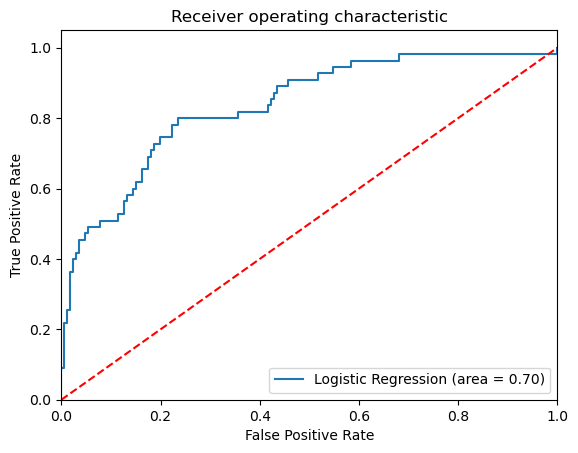

In [67]:
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve
logit_roc_auc = roc_auc_score(y_test, classifier.predict(X_test))
fpr, tpr, thresholds = roc_curve(y_test, classifier.predict_proba(X_test)[:,1])
plt.figure()
plt.plot(fpr, tpr, label='Logistic Regression (area = %0.2f)' % logit_roc_auc)
plt.plot([0, 1], [0, 1],'r--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver operating characteristic')
plt.legend(loc="lower right")
plt.savefig('Log_ROC')
plt.show()

### Recursive Feature Elimination

In [68]:
y_label_list = ['Skp2', 'p21', 'pp21', 'Cdh1', 'Myc', 'CycD', 'CycDp21', 'Rb', 'pRb', 'E2F', 'RbE2F',
                'CycE', 'CycEp21', 'CycA', 'CycAp21', 'CycB', 'CycBp21', 'Cdc20']

In [69]:
from sklearn.feature_selection import RFE
classifier = LogisticRegression(random_state = 0)
classifier.fit(X_train, y_train)
y_pred = classifier.predict(X_test)

In [70]:
rfe = RFE(classifier, n_features_to_select=1)
rfe = rfe.fit(X_train, y_train)
res = "\n".join("{} {}".format(x, y) for x, y in zip(y_label_list, rfe.ranking_))
print(res)

Skp2 17
p21 7
pp21 13
Cdh1 16
Myc 18
CycD 12
CycDp21 8
Rb 2
pRb 9
E2F 6
RbE2F 5
CycE 1
CycEp21 3
CycA 4
CycAp21 10
CycB 11
CycBp21 14
Cdc20 15


### Fitting top 5 params

In [71]:
X_new = X_train[:,[11,7,12,13,10]]


In [72]:
classifier = LogisticRegression(random_state = 0)
classifier.fit(X_new, y_train)
X_test_new = X_test[:,[11,7,12,13,10]]
y_pred = classifier.predict(X_test_new)


In [73]:
from sklearn.model_selection import cross_val_score
accuracies = cross_val_score(estimator = classifier, X = X_train, y = y_train, cv = 10)
print("Accuracy: {:.2f} %".format(accuracies.mean()*100))
print("Standard Deviation: {:.2f} %".format(accuracies.std()*100))

Accuracy: 80.50 %
Standard Deviation: 3.09 %


In [74]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

         0.0       0.84      0.90      0.87       166
         1.0       0.63      0.49      0.55        55

    accuracy                           0.80       221
   macro avg       0.74      0.70      0.71       221
weighted avg       0.79      0.80      0.79       221



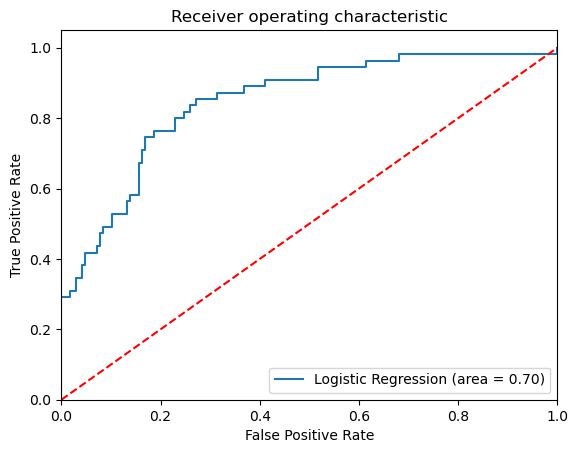

In [75]:
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve
logit_roc_auc = roc_auc_score(y_test, classifier.predict(X_test_new))
fpr, tpr, thresholds = roc_curve(y_test, classifier.predict_proba(X_test_new)[:,1])
plt.figure()
plt.plot(fpr, tpr, label='Logistic Regression (area = %0.2f)' % logit_roc_auc)
plt.plot([0, 1], [0, 1],'r--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver operating characteristic')
plt.legend(loc="lower right")
plt.savefig('Log_ROC')
plt.show()

### 10 hours before div

In [76]:
dataset_0, imts_erl_int_0 = splitG1(time_win_erl_int, erl_int_prot_df, 0)

In [77]:
dataset_10, imts_erl_int_10 = splitG1(time_win_erl_int, erl_int_prot_df, 10)

In [78]:
dataset_0.iloc[:5,:]

,0,1,2,3,4,5,6,7,8,9,...,351,352,353,354,355,356,357,358,359,360
0,0.264151,0.264151,0.264151,0.264151,0.264151,0.264151,0.264151,0.264151,0.283019,0.283019,...,0.580,0.575,0.550,0.535,0.565,0.585,0.575,0.575,0.565,0.0
1,0.320755,0.320755,0.320755,0.320755,0.301887,0.320755,0.320755,0.320755,0.320755,0.320755,...,0.880,0.860,0.865,0.840,0.835,0.830,0.840,0.840,0.845,1.0
2,0.132075,0.132075,0.132075,0.132075,0.132075,0.132075,0.132075,0.132075,0.132075,0.132075,...,0.625,0.600,0.605,0.605,0.585,0.590,0.590,0.605,0.585,0.0
3,0.169811,0.169811,0.169811,0.169811,0.169811,0.150943,0.132075,0.132075,0.132075,0.150943,...,0.755,0.760,0.730,0.735,0.750,0.735,0.760,0.730,0.735,0.0
4,0.283019,0.283019,0.264151,0.264151,0.264151,0.283019,0.283019,0.283019,0.283019,0.264151,...,0.905,0.895,0.880,0.870,0.850,0.840,0.820,0.835,0.845,0.0


In [79]:
dataset_10.iloc[:5,:]

,0,1,2,3,4,5,6,7,8,9,...,351,352,353,354,355,356,357,358,359,360
0,0.056604,0.056604,0.056604,0.056604,0.056604,0.056604,0.056604,0.056604,0.056604,0.056604,...,0.055,0.040,0.045,0.050,0.055,0.055,0.045,0.050,0.06,0.0
1,0.226415,0.226415,0.226415,0.226415,0.207547,0.207547,0.207547,0.207547,0.207547,0.207547,...,0.085,0.090,0.075,0.085,0.085,0.095,0.105,0.110,0.10,1.0
2,0.037736,0.037736,0.037736,0.037736,0.037736,0.037736,0.037736,0.037736,0.037736,0.037736,...,0.070,0.055,0.065,0.065,0.060,0.075,0.070,0.075,0.09,0.0
3,0.094340,0.075472,0.018868,0.018868,0.018868,0.018868,0.018868,0.018868,0.018868,0.018868,...,0.090,0.090,0.095,0.085,0.100,0.105,0.115,0.115,0.11,0.0
4,0.018868,0.018868,0.018868,0.018868,0.018868,0.018868,0.018868,0.018868,0.018868,0.018868,...,0.130,0.130,0.175,0.175,0.195,0.220,0.215,0.235,0.23,0.0


In [80]:
X = dataset_10.iloc[:, 9::20].values
y = dataset_10.iloc[:, -1].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 0)

In [82]:
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

In [83]:
reducer_1 = umap.UMAP(
        n_neighbors=10,
        min_dist=0.02,
        n_components=2,
        metric='euclidean',
        random_state=5,
        low_memory=True        
        ).fit(X_train)

embedding_X_train = reducer_1.transform(X_train)

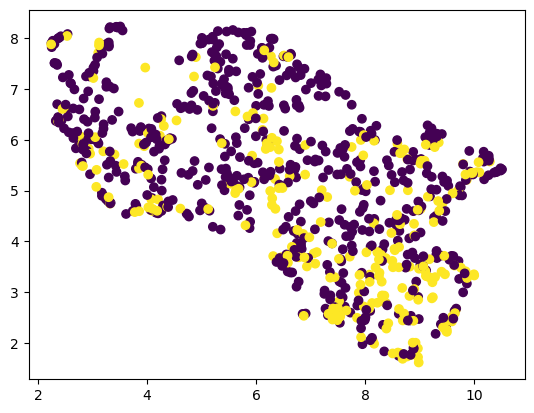

In [84]:
plt.figure()
plt.scatter(embedding_X_train[:,0], embedding_X_train[:,1], c=y_train)

In [85]:
classifier = LogisticRegression(random_state = 0)
classifier.fit(X_train, y_train)
y_pred = classifier.predict(X_test)

In [86]:
accuracies = cross_val_score(estimator = classifier, X = X_train, y = y_train, cv = 10)
print("Accuracy: {:.2f} %".format(accuracies.mean()*100))
print("Standard Deviation: {:.2f} %".format(accuracies.std()*100))

Accuracy: 72.34 %
Standard Deviation: 2.37 %


In [87]:
from sklearn.feature_selection import RFE
classifier = LogisticRegression(random_state = 0)
classifier.fit(X_train, y_train)
y_pred = classifier.predict(X_test)

In [88]:
rfe = RFE(classifier, n_features_to_select=1)
rfe = rfe.fit(X_train, y_train)
res = "\n".join("{} {}".format(x, y) for x, y in zip(y_label_list, rfe.ranking_))
print(res)

Skp2 5
p21 18
pp21 3
Cdh1 15
Myc 14
CycD 10
CycDp21 8
Rb 17
pRb 2
E2F 4
RbE2F 7
CycE 1
CycEp21 13
CycA 12
CycAp21 9
CycB 6
CycBp21 16
Cdc20 11


In [89]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

         0.0       0.78      0.91      0.84       166
         1.0       0.44      0.22      0.29        55

    accuracy                           0.74       221
   macro avg       0.61      0.56      0.57       221
weighted avg       0.70      0.74      0.70       221



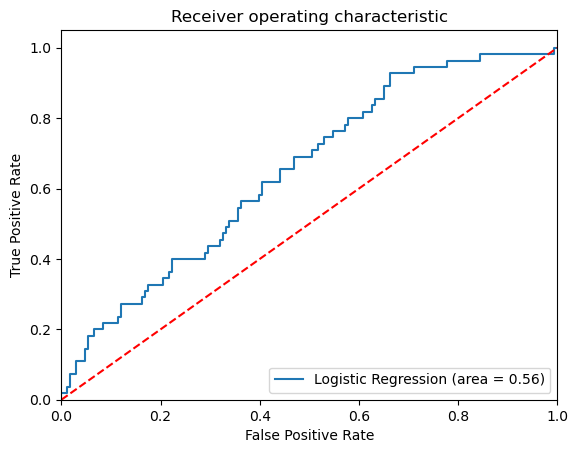

In [90]:
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve
logit_roc_auc = roc_auc_score(y_test, classifier.predict(X_test))
fpr, tpr, thresholds = roc_curve(y_test, classifier.predict_proba(X_test)[:,1])
plt.figure()
plt.plot(fpr, tpr, label='Logistic Regression (area = %0.2f)' % logit_roc_auc)
plt.plot([0, 1], [0, 1],'r--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver operating characteristic')
plt.legend(loc="lower right")
plt.savefig('Log_ROC')
plt.show()

In [91]:
from matplotlib.colors import ListedColormap
X_set, y_set = X_train, y_train
X1, X2 = np.meshgrid(np.arange(start = X_set[:, 0].min() - 1, stop = X_set[:, 0].max() + 1, step = 0.01),
                     np.arange(start = X_set[:, 1].min() - 1, stop = X_set[:, 1].max() + 1, step = 0.01))
plt.contourf(X1, X2, classifier.predict(np.array([X1.ravel(), X2.ravel()]).T).reshape(X1.shape),
             alpha = 0.75, cmap = ListedColormap(('red', 'green', 'blue')))
plt.xlim(X1.min(), X1.max())
plt.ylim(X2.min(), X2.max())
for i, j in enumerate(np.unique(y_set)):
    plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],
                c = ListedColormap(('red', 'green', 'blue'))(i), label = j)
plt.title('Logistic Regression (Training set)')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend()
plt.show()

ValueError: X has 2 features, but LogisticRegression is expecting 18 features as input.

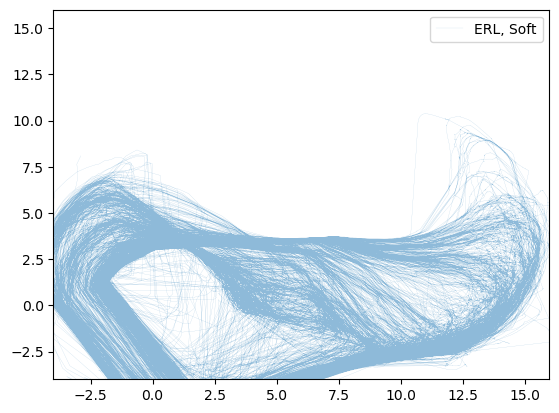

In [92]:
trk_len = int(len(all_prot_tmp)/6)
fig = plt.figure()
plt.plot(embedding_all_prot[1*trk_len:2*trk_len,0], embedding_all_prot[1*trk_len:2*trk_len,1], lw=0.1, alpha=0.5, label='ERL, Soft')
#plt.plot(embedding_all_prot[3*trk_len:4*trk_len,0], embedding_all_prot[3*trk_len:4*trk_len,1], lw=0.1, alpha=0.5, label='ERL, Int.')
#plt.plot(embedding_all_prot[5*trk_len:6*trk_len,0], embedding_all_prot[5*trk_len:6*trk_len,1], lw=0.1, alpha=0.5, label='ERL, Stiff')
plt.xlim(-4, 16)
plt.ylim(-4, 16)
plt.legend()

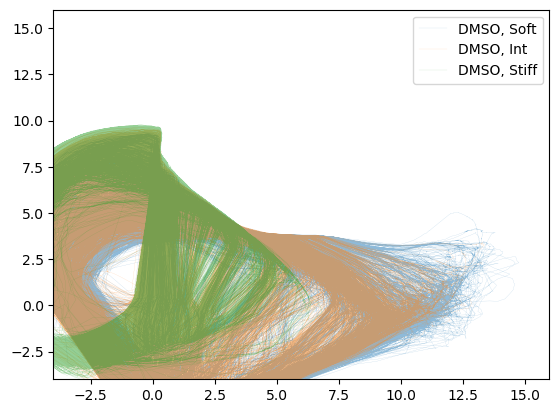

In [93]:
trk_len = int(len(all_prot_tmp)/6)
fig = plt.figure()
plt.plot(embedding_all_prot[0*trk_len:1*trk_len,0], embedding_all_prot[0*trk_len:1*trk_len,1], lw=0.1, alpha=0.5, label='DMSO, Soft')
plt.plot(embedding_all_prot[2*trk_len:3*trk_len,0], embedding_all_prot[2*trk_len:3*trk_len,1], lw=0.1, alpha=0.5, label='DMSO, Int')
plt.plot(embedding_all_prot[4*trk_len:5*trk_len,0], embedding_all_prot[4*trk_len:5*trk_len,1], lw=0.1, alpha=0.5, label='DMSO, Stiff')
plt.xlim(-4, 16)
plt.ylim(-4, 16)
plt.legend()

In [94]:
all_prot_tmp.shape

(599982, 360)

In [95]:
all_prot_tmp[:10,:10]

array([[0.22641509, 0.22641509, 0.22641509, 0.20754717, 0.20754717,
        0.20754717, 0.20754717, 0.20754717, 0.20754717, 0.20754717],
       [0.20754717, 0.20754717, 0.20754717, 0.20754717, 0.20754717,
        0.20754717, 0.20754717, 0.20754717, 0.22641509, 0.22641509],
       [0.20754717, 0.20754717, 0.20754717, 0.22641509, 0.22641509,
        0.22641509, 0.22641509, 0.22641509, 0.22641509, 0.22641509],
       [0.22641509, 0.22641509, 0.22641509, 0.22641509, 0.22641509,
        0.24528302, 0.24528302, 0.24528302, 0.24528302, 0.24528302],
       [0.24528302, 0.24528302, 0.24528302, 0.24528302, 0.24528302,
        0.24528302, 0.24528302, 0.24528302, 0.24528302, 0.24528302],
       [0.24528302, 0.24528302, 0.24528302, 0.24528302, 0.24528302,
        0.26415094, 0.26415094, 0.26415094, 0.28301887, 0.30188679],
       [0.26415094, 0.26415094, 0.26415094, 0.28301887, 0.30188679,
        0.30188679, 0.30188679, 0.30188679, 0.30188679, 0.30188679],
       [0.30188679, 0.30188679, 0.3018867